# Traffic Volume Time-Series Forecasting

This notebook documents our team's workflow for exploring, cleaning, and preparing traffic data, investigating analytical questions, and building a one-hour-ahead traffic-volume forecasting model.


## 1.1 Problem Definition and Motivation

Our project aims to predict traffic volume one hour ahead using historical traffic observations, time-related features, and available weather information.

We chose this problem because traffic patterns change throughout the day. Some hours are relatively quiet, while others experience much heavier traffic. When busy periods are not anticipated, road users may experience delays and traffic authorities may find it harder to organize traffic efficiently.

We want to investigate whether a short-term forecast could help people and authorities prepare for periods when traffic volume is expected to be high. For example, traffic authorities could use such information when planning traffic-management measures, such as adjusting traffic-light timing or positioning traffic officers. Drivers and commuters could also use traffic information to plan their journeys.

Weather is worth investigating because rain, snow, and other conditions can affect driving conditions. However, our target is **traffic volume**, not accidents, vehicle speed, or congestion directly. Predicting accidents would require additional accident and road-condition data.


## 1.2 Dataset Selection and Justification

We selected the **Metro Interstate Traffic Volume** dataset because it contains a substantial number of observations and meaningful variables for investigating traffic patterns and developing forecasting experiments. These include timestamps, traffic volume, temperature, rainfall, snowfall, cloud coverage, and weather descriptions.

The dataset allows us to explore how traffic changes by hour and day of the week, examine whether previous traffic volumes are associated with current traffic, create lagged and moving-average features, and compare forecasting models. It therefore provides a practical way for our team to apply time-series analysis and machine-learning techniques to a real-world problem.

The dataset describes traffic on Interstate 94 in the Minneapolis–St. Paul area of the United States. Its methods may provide a starting point for similar work elsewhere, but its results cannot automatically be generalized to Rwanda. Local traffic data would be needed to assess performance on Rwandan roads.


## 1.3 Forecasting Objective and Scope

- **Prediction target:** `traffic_volume`, the recorded number of vehicles for an hour.
- **Forecast horizon:** one hour ahead.
- **Available inputs:** historical traffic volume, hour, day of the week, weekend indicator, and available weather measurements.
- **Practical purpose:** investigate whether forecasts can help identify likely high- and low-volume periods.

A practical forecasting system must only use information available when the prediction is made. Our engineered lagged features and moving averages are based on previous traffic observations. The dataset contains observed weather rather than future weather forecasts, so using weather recorded for the hour being predicted would not represent a fully operational real-time forecast. We will keep this limitation in mind when interpreting the model and considering future improvements.


### Required Libraries

In [47]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
import joblib


In [2]:
df = pd.read_csv("data/Metro_Interstate_Traffic_Volume.csv")

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nData types:")
print(df.info())

Dataset shape: (48204, 9)

Column names:
['holiday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main', 'weather_description', 'date_time', 'traffic_volume']

First five rows:


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918



Data types:
holiday                    str
temp                   float64
rain_1h                float64
snow_1h                float64
clouds_all               int64
weather_main               str
weather_description        str
date_time                  str
traffic_volume           int64
dtype: object

Data types:
<class 'pandas.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     str    
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  str    
 6   weather_description  48204 non-null  str    
 7   date_time            48204 non-null  str    
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), str(

### 2. Data Quality Assessment

Before cleaning the dataset, we will assess missing values, duplicate records, timestamp validity, chronological ordering, and sampling frequency. These checks will help identify potential problems that could affect the reliability of the exploratory analysis and traffic-volume forecasting.

In [3]:

# Check missing values in each column
print("Missing values per column:")
print(df.isnull().sum())

print("\nMissing values as percentages:")
print((df.isnull().mean() * 100).round(2))

# Check duplicate rows
print("\nNumber of fully duplicated rows:")
print(df.duplicated().sum())

# Check duplicate timestamps
print("\nNumber of duplicated timestamps:")
print(df["date_time"].duplicated().sum())


Missing values per column:
holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
traffic_volume             0
dtype: int64

Missing values as percentages:
holiday                99.87
temp                    0.00
rain_1h                 0.00
snow_1h                 0.00
clouds_all              0.00
weather_main            0.00
weather_description     0.00
date_time               0.00
traffic_volume          0.00
dtype: float64

Number of fully duplicated rows:
17

Number of duplicated timestamps:
7629


In [4]:

# Convert timestamps into datetime values
df["date_time"] = pd.to_datetime(
    df["date_time"],
    errors="coerce"
)

# Check timestamps that could not be converted
print("Invalid or missing timestamps:",
      df["date_time"].isna().sum())

# Check chronological ordering
print("Already in chronological order:",
      df["date_time"].is_monotonic_increasing)

# Display earliest and latest timestamps
print("Earliest timestamp:", df["date_time"].min())
print("Latest timestamp:", df["date_time"].max())


Invalid or missing timestamps: 0
Already in chronological order: True
Earliest timestamp: 2012-10-02 09:00:00
Latest timestamp: 2018-09-30 23:00:00


In [5]:

# Sort a separate timestamp series for reliable interval analysis
timestamps = df["date_time"].dropna().sort_values()

# Calculate the time difference between consecutive observations
time_gaps = timestamps.diff().dropna()

print("Most common time intervals:")
print(time_gaps.value_counts().head(10))

print("\nNumber of intervals equal to one hour:",
      (time_gaps == pd.Timedelta(hours=1)).sum())

print("\nNumber of intervals longer than one hour:",
      (time_gaps > pd.Timedelta(hours=1)).sum())

print("\nNumber of intervals shorter than one hour:",
      (time_gaps < pd.Timedelta(hours=1)).sum())


Most common time intervals:
date_time
0 days 01:00:00    37986
0 days 00:00:00     7629
0 days 02:00:00     2192
0 days 03:00:00      201
0 days 04:00:00       59
0 days 05:00:00       33
0 days 06:00:00       17
0 days 08:00:00       13
0 days 10:00:00       13
0 days 09:00:00       12
Name: count, dtype: int64

Number of intervals equal to one hour: 37986

Number of intervals longer than one hour: 2588

Number of intervals shorter than one hour: 7629


In [6]:

# Show examples of repeated timestamps
repeated = df[
    df["date_time"].duplicated(keep=False)
].sort_values("date_time")

print("Rows involved in repeated timestamps:",
      len(repeated))

display(repeated.head(12))

# Count how many unique traffic-volume values occur
# at each timestamp
traffic_values_per_time = (
    df.groupby("date_time")["traffic_volume"]
      .nunique()
)

print("\nTimestamps with multiple traffic-volume values:",
      (traffic_values_per_time > 1).sum())

print("Timestamps with repeated records but one traffic-volume value:",
      ((df["date_time"].duplicated(keep=False)).sum()))


Rows involved in repeated timestamps: 13074


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
178,NaN,281.25,0.0,0.0,99,Rain,light rain,2012-10-10 07:00:00,6793
179,NaN,281.25,0.0,0.0,99,Drizzle,light intensity drizzle,2012-10-10 07:00:00,6793
180,NaN,280.10,0.0,0.0,99,Rain,light rain,2012-10-10 08:00:00,6283
181,NaN,280.10,0.0,0.0,99,Drizzle,light intensity drizzle,2012-10-10 08:00:00,6283
182,NaN,279.61,0.0,0.0,99,Rain,light rain,2012-10-10 09:00:00,5680
183,NaN,279.61,0.0,0.0,99,Drizzle,light intensity drizzle,2012-10-10 09:00:00,5680
269,NaN,282.43,0.0,0.0,57,Drizzle,light intensity drizzle,2012-10-14 09:00:00,2685
270,NaN,282.43,0.0,0.0,57,Mist,mist,2012-10-14 09:00:00,2685
271,NaN,282.43,0.0,0.0,57,Haze,haze,2012-10-14 09:00:00,2685
272,NaN,282.33,0.0,0.0,57,Drizzle,light intensity drizzle,2012-10-14 10:00:00,3370



Timestamps with multiple traffic-volume values: 0
Timestamps with repeated records but one traffic-volume value: 13074


In [7]:

# Count distinct timestamps that occur more than once
timestamp_counts = df["date_time"].value_counts()

print(
    "Distinct timestamps occurring more than once:",
    (timestamp_counts > 1).sum()
)

# Check whether records sharing a timestamp differ in other columns
duplicate_groups = df[
    df["date_time"].duplicated(keep=False)
].groupby("date_time")

conflicting_groups = sum(
    1 for _, group in duplicate_groups
    if len(group.drop(columns="date_time").drop_duplicates()) > 1
)

print("Repeated timestamps with differing other-column values:",
      conflicting_groups)

# Check exact duplicate rows
print("Exact duplicate rows:", df.duplicated().sum())


Distinct timestamps occurring more than once: 5445
Repeated timestamps with differing other-column values: 5430
Exact duplicate rows: 17


In [8]:

# Select a few timestamps that have different records
repeated = df[
    df["date_time"].duplicated(keep=False)
].sort_values("date_time")

example_times = (
    repeated.groupby("date_time")
    .filter(
        lambda group: len(group.drop(columns="date_time")
                          .drop_duplicates()) > 1
    )["date_time"]
    .drop_duplicates()
    .head(3)
)

for timestamp in example_times:
    print(f"\nTimestamp: {timestamp}")
    display(
        df[df["date_time"] == timestamp]
    )



Timestamp: 2012-10-10 07:00:00


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
178,NaN,281.25,0.0,0.0,99,Rain,light rain,2012-10-10 07:00:00,6793
179,NaN,281.25,0.0,0.0,99,Drizzle,light intensity drizzle,2012-10-10 07:00:00,6793



Timestamp: 2012-10-10 08:00:00


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
180,NaN,280.1,0.0,0.0,99,Rain,light rain,2012-10-10 08:00:00,6283
181,NaN,280.1,0.0,0.0,99,Drizzle,light intensity drizzle,2012-10-10 08:00:00,6283



Timestamp: 2012-10-10 09:00:00


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
182,NaN,279.61,0.0,0.0,99,Rain,light rain,2012-10-10 09:00:00,5680
183,NaN,279.61,0.0,0.0,99,Drizzle,light intensity drizzle,2012-10-10 09:00:00,5680


In [9]:
# Numerical columns we want to compare
numeric_cols = [
    "temp",
    "rain_1h",
    "snow_1h",
    "clouds_all",
    "traffic_volume"
]

# Count timestamps where each numerical column has
# more than one distinct value
for col in numeric_cols:
    unique_counts = df.groupby("date_time")[col].nunique()
    conflicts = (unique_counts > 1).sum()

    print(f"{col}: {conflicts} timestamps with conflicting values")


temp: 78 timestamps with conflicting values
rain_1h: 9 timestamps with conflicting values
snow_1h: 0 timestamps with conflicting values
clouds_all: 32 timestamps with conflicting values
traffic_volume: 0 timestamps with conflicting values


In [10]:
# Find a timestamp where temperature differs
temp_counts = df.groupby("date_time")["temp"].nunique()
example_time = temp_counts[temp_counts > 1].index[0]

print("Example timestamp:", example_time)

display(
    df[df["date_time"] == example_time][
        ["date_time", "temp", "rain_1h", "clouds_all",
         "weather_main", "weather_description", "traffic_volume"]
    ]
)

Example timestamp: 2012-11-04 01:00:00


,date_time,temp,rain_1h,clouds_all,weather_main,weather_description,traffic_volume
878,2012-11-04 01:00:00,275.60,0.0,90,Clouds,overcast clouds,730
879,2012-11-04 01:00:00,275.77,0.0,90,Clouds,overcast clouds,730


In [11]:

# Preserve the original dataset
df_original = df.copy()

# Remove exact duplicate rows
df_clean = df.drop_duplicates().copy()

# Define a function to select the most frequent non-missing value
def most_frequent_value(series):
    values = series.dropna()

    if values.empty:
        return None

    return values.mode().iloc[0]

# Consolidate records to one row per timestamp
df_clean = (
    df_clean.groupby("date_time", as_index=False)
    .agg({
        "holiday": most_frequent_value,
        "temp": "mean",
        "rain_1h": "mean",
        "snow_1h": "mean",
        "clouds_all": "mean",
        "weather_main": most_frequent_value,
        "weather_description": most_frequent_value,
        "traffic_volume": "first"
    })
    .sort_values("date_time")
    .reset_index(drop=True)
)

print("Original rows:", len(df_original))
print("Cleaned rows:", len(df_clean))
print("Remaining duplicate timestamps:",
      df_clean["date_time"].duplicated().sum())
print("Missing values after consolidation:")
print(df_clean.isnull().sum())


Original rows: 48204
Cleaned rows: 40575
Remaining duplicate timestamps: 0
Missing values after consolidation:
date_time                  0
holiday                40522
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
traffic_volume             0
dtype: int64


In [12]:

# Calculate the time difference between consecutive cleaned records
gaps = df_clean["date_time"].diff()

print("Most common intervals after cleaning:")
print(gaps.value_counts().head(10))

# Identify intervals longer than one hour
long_gaps = gaps[gaps > pd.Timedelta(hours=1)]

print("\nNumber of intervals longer than one hour:",
      len(long_gaps))

print("\nTotal hours missing between observed timestamps:",
      int((long_gaps / pd.Timedelta(hours=1) - 1).sum()))


Most common intervals after cleaning:
date_time
0 days 01:00:00    37986
0 days 02:00:00     2192
0 days 03:00:00      201
0 days 04:00:00       59
0 days 05:00:00       33
0 days 06:00:00       17
0 days 08:00:00       13
0 days 10:00:00       13
0 days 09:00:00       12
0 days 07:00:00       10
Name: count, dtype: int64

Number of intervals longer than one hour: 2588

Total hours missing between observed timestamps: 11976


### Investigating Missing Time Intervals

In this step, I will identify where the largest gaps occur in the time series. This will help me understand whether missing hourly observations are spread throughout the dataset or concentrated in particular periods. I will use this information to decide how to prepare the data for time-series forecasting without inventing traffic-volume values.

In [13]:
# Calculate the time difference between consecutive records
time_diff = df_clean["date_time"].diff()

# Find gaps longer than one hour
gap_positions = time_diff[time_diff > pd.Timedelta(hours=1)].index

# Describe each gap
gap_details = pd.DataFrame({
    "last_observed_time": df_clean.loc[gap_positions - 1, "date_time"].values,
    "next_observed_time": df_clean.loc[gap_positions, "date_time"].values,
    "gap_hours": (
        df_clean.loc[gap_positions, "date_time"].values -
        df_clean.loc[gap_positions - 1, "date_time"].values
    ) / pd.Timedelta(hours=1)
})

gap_details["missing_hours"] = gap_details["gap_hours"] - 1

# Show the 10 largest gaps
print("Ten largest gaps in the time series:")
print(gap_details.sort_values("gap_hours", ascending=False).head(10).to_string(index=False))

Ten largest gaps in the time series:
 last_observed_time  next_observed_time  gap_hours  missing_hours
2014-08-08 01:00:00 2015-06-11 20:00:00     7387.0         7386.0
2013-10-27 01:00:00 2013-11-06 04:00:00      243.0          242.0
2015-06-14 20:00:00 2015-06-19 18:00:00      118.0          117.0
2014-04-29 08:00:00 2014-05-04 05:00:00      117.0          116.0
2015-10-23 11:00:00 2015-10-27 08:00:00       93.0           92.0
2014-07-27 16:00:00 2014-07-30 09:00:00       65.0           64.0
2013-08-31 00:00:00 2013-09-01 23:00:00       47.0           46.0
2015-06-22 18:00:00 2015-06-24 04:00:00       34.0           33.0
2014-08-02 02:00:00 2014-08-03 11:00:00       33.0           32.0
2013-09-03 02:00:00 2013-09-04 08:00:00       30.0           29.0


The output shows that missing observations are not evenly distributed. Most importantly, there is an unusually large gap between August 8, 2014, and June 11, 2015.

That gap is 7,386 missing hours, or about 308 days. This is much larger than the other gaps, which range from 29 to 242 missing hours among the ten largest gaps shown.

This tells me that:
- The dataset does not contain a continuous hourly record.
- The largest gap could significantly affect forecasting if we treat the data as one uninterrupted time series.
- I should not fill such a long gap with invented traffic values.
- I need to investigate whether the dataset contains separate periods of observations before deciding how to prepare it for forecasting.

### Identifying Continuous Observation Periods

In this step, I will divide the dataset into continuous observation periods. Whenever the gap between consecutive records is longer than one hour, I will mark the beginning of a new period. I will then compare the lengths of these periods to understand how much continuous hourly data is available for forecasting. I will not fill missing traffic values with zero.

In [14]:
# Calculate the time difference between consecutive records
time_diff = df_clean["date_time"].diff()

# Start a new period whenever the gap is longer than one hour
new_period = time_diff.isna() | (time_diff > pd.Timedelta(hours=1))
df_clean["period_id"] = new_period.cumsum()

# Summarize each period
period_summary = (
    df_clean.groupby("period_id")
    .agg(
        start_time=("date_time", "min"),
        end_time=("date_time", "max"),
        observations=("date_time", "count")
    )
    .reset_index()
)

period_summary["duration_days"] = (
    (period_summary["end_time"] - period_summary["start_time"])
    .dt.total_seconds() / 86400
)

print("Number of continuous periods:", len(period_summary))
print("\nTen longest continuous periods:")
print(
    period_summary.sort_values("observations", ascending=False)
    .head(10)
    .to_string(index=False)
)

Number of continuous periods: 2589

Ten longest continuous periods:
 period_id          start_time            end_time  observations  duration_days
      2565 2017-04-13 10:00:00 2017-07-02 04:00:00          1915      79.750000
      2587 2018-06-02 03:00:00 2018-08-07 06:00:00          1588      66.125000
      2556 2016-12-18 19:00:00 2017-02-13 15:00:00          1365      56.833333
      2515 2016-07-13 18:00:00 2016-08-24 16:00:00          1007      41.916667
      2571 2017-09-28 00:00:00 2017-11-08 01:00:00           986      41.041667
      2589 2018-08-23 03:00:00 2018-09-30 23:00:00           933      38.833333
      2579 2018-01-31 03:00:00 2018-03-10 01:00:00           911      37.916667
       779 2014-01-26 09:00:00 2014-03-04 14:00:00           894      37.208333
      2585 2018-03-29 03:00:00 2018-05-05 01:00:00           887      36.916667
      2568 2017-07-10 16:00:00 2017-08-16 03:00:00           876      36.458333


I found 2,589 continuous observation periods in my cleaned dataset. This means the data is divided into many separate periods because some timestamps are missing between consecutive records.

The longest period contains 1,915 observations over approximately 79.75 days, from April 13, 2017, to July 2, 2017. The other long periods are also limited to a few weeks or months.

This tells me that I cannot treat the entire dataset as one continuous hourly time series without addressing the gaps. I will preserve the original timestamps and avoid filling missing traffic-volume values with zero. Before forecasting, I will investigate the observation frequency and select a suitable continuous period or approach for handling the gaps.

### Investigating Missing Holiday Values

In this step, I will examine the recorded values in the `holiday` column. I will count the occurrences of each holiday label and check how many values are missing. This will help me understand the available holiday information before choosing an appropriate strategy for handling the missing values.

In [15]:
print("Holiday value counts, including missing values:")
print(df_original["holiday"].value_counts(dropna=False))

print("\nNumber of non-missing holiday values:")
print(df_original["holiday"].notna().sum())

print("\nNumber of distinct recorded holiday labels:")
print(df_original["holiday"].nunique())

Holiday value counts, including missing values:
holiday
NaN                          48143
Labor Day                        7
Thanksgiving Day                 6
Christmas Day                    6
New Years Day                    6
Martin Luther King Jr Day        6
Columbus Day                     5
Veterans Day                     5
Washingtons Birthday             5
Memorial Day                     5
Independence Day                 5
State Fair                       5
Name: count, dtype: int64

Number of non-missing holiday values:
61

Number of distinct recorded holiday labels:
11


### Examining Recorded Holidays and Traffic Volume

In this step, I will examine the dates, holiday labels, and traffic volumes for observations where the `holiday` column is not missing. This will help me understand how the recorded holiday information aligns with the timestamps and whether it may be useful for analyzing traffic patterns.

In [16]:
# Select rows where a holiday is recorded
holiday_rows = df_original[df_original["holiday"].notna()].copy()

print("Recorded holiday observations:")
print(
    holiday_rows[["date_time", "holiday", "traffic_volume"]]
    .sort_values("date_time")
    .to_string(index=False)
)

Recorded holiday observations:
 date_time                   holiday  traffic_volume
2012-10-08              Columbus Day             455
2012-11-12              Veterans Day            1000
2012-11-22          Thanksgiving Day             919
2012-12-25             Christmas Day             803
2013-01-01             New Years Day            1439
2013-02-18      Washingtons Birthday             556
2013-05-27              Memorial Day             863
2013-07-04          Independence Day            1060
2013-08-22                State Fair             661
2013-09-02                 Labor Day            1041
2013-10-14              Columbus Day             615
2013-11-11              Veterans Day             514
2013-11-28          Thanksgiving Day             929
2013-12-25             Christmas Day             712
2014-01-01             New Years Day            1395
2014-01-20 Martin Luther King Jr Day             480
2014-02-17      Washingtons Birthday             583
2014-05-26     

### Interpretation of Recorded Holiday Observations

I observed that the recorded holiday dates have different traffic-volume values. For example, the dataset records a traffic volume of 455 on Columbus Day in 2012, 919 on Thanksgiving Day in 2012, and 1,439 on New Year's Day in 2013.

These observations suggest that traffic volume can vary on holidays. However, I cannot conclude that holidays always have lower traffic because I have not yet compared these observations with traffic volumes on ordinary days at comparable hours.

I also noticed that some holiday observations appear more than once, such as Labor Day on September 3, 2018. This is expected because the dataset can contain multiple hourly observations on the same holiday date, although I will check whether the repeated rows represent different timestamps or duplicate records.

The holiday column may be useful for understanding traffic patterns, but I need to investigate its relationship with the dates before deciding how to handle its missing values.

### Checking Holiday Dates and Timestamps

In this step, I will compare the dates recorded in the `holiday` column with the dates in the `date_time` column. I will check how many distinct dates have holiday labels and whether each recorded holiday label appears on a single date or multiple dates. This will help me understand how the holiday information is represented in the dataset before deciding how to handle missing values.

In [17]:
holiday_rows = df_original[df_original["holiday"].notna()].copy()

holiday_rows["date"] = pd.to_datetime(holiday_rows["date_time"]).dt.date

print("Number of rows with recorded holidays:",
      len(holiday_rows))

print("Number of distinct dates with recorded holidays:",
      holiday_rows["date"].nunique())

print("\nDistinct dates per holiday label:")
print(
    holiday_rows.groupby("holiday")["date"]
    .nunique()
    .sort_values(ascending=False)
)

Number of rows with recorded holidays: 61
Number of distinct dates with recorded holidays: 53

Distinct dates per holiday label:
holiday
Christmas Day                5
Columbus Day                 5
Independence Day             5
Labor Day                    5
Memorial Day                 5
New Years Day                5
State Fair                   5
Veterans Day                 5
Thanksgiving Day             5
Washingtons Birthday         5
Martin Luther King Jr Day    3
Name: date, dtype: int64


### Interpretation of Holiday Dates and Timestamps

I found 61 rows with recorded holiday labels, covering 53 distinct dates. The holiday labels appear across multiple years, with most labels occurring on five distinct dates and Martin Luther King Jr Day occurring on three dates.

This confirms that the holiday information is recorded for only a small portion of the dataset. However, these results do not prove that missing holiday values mean ordinary days without holidays.

I will therefore avoid automatically replacing all missing holiday values with `No Holiday`. Instead, I will investigate whether the recorded holiday dates follow a recognizable pattern and whether I can use the timestamps to identify holidays reliably.

### Examining the Time-of-Day Coverage of Holiday Records

In this step, I will examine the hours at which holiday observations are recorded. This will help me determine whether the holiday column identifies only selected hourly observations on a holiday or whether it labels all available observations throughout a holiday date. This distinction is important before deciding how to handle missing holiday values.

In [18]:
holiday_rows = df_original[df_original["holiday"].notna()].copy()

holiday_rows["date_time"] = pd.to_datetime(holiday_rows["date_time"])
holiday_rows["date"] = holiday_rows["date_time"].dt.date
holiday_rows["hour"] = holiday_rows["date_time"].dt.hour

print("Number of recorded holiday observations by hour:")
print(holiday_rows["hour"].value_counts().sort_index())

print("\nNumber of recorded holiday observations per date:")
print(holiday_rows.groupby("date").size().value_counts().sort_index())

Number of recorded holiday observations by hour:
hour
0    61
Name: count, dtype: int64

Number of recorded holiday observations per date:
1    46
2     6
3     1
Name: count, dtype: int64


### Interpretation of Holiday Observation Coverage

I found that all 61 recorded holiday observations occur at hour 00:00 (midnight). This means the holiday labels are not recorded across all hours of the day in the original dataset.

I also found that 46 dates have one recorded holiday observation, six dates have two observations, and one date has three observations. Since every recorded observation occurs at midnight, the holiday column does not directly provide a complete holiday label for every hourly traffic observation.

These findings suggest that the missing holiday values may reflect how the dataset records holiday information rather than proving that the remaining dates are ordinary days. I will investigate the dataset's date and holiday patterns further before deciding how to handle these missing values.

### Checking Holiday Labels Across Each Date

In this step, I will check whether each recorded holiday label corresponds to a date that contains other hourly observations with missing holiday labels. This will help me determine whether the holiday label could be assigned to all observations on the same date, rather than treating every missing value as a non-holiday.

In [19]:
# Work with the original rows to inspect the recorded holiday labels
holiday_check = df_original.copy()
holiday_check["date_time"] = pd.to_datetime(holiday_check["date_time"])
holiday_check["date"] = holiday_check["date_time"].dt.date

# Identify dates with at least one recorded holiday label
holiday_dates = holiday_check.loc[
    holiday_check["holiday"].notna(), ["date", "holiday"]
].drop_duplicates()

# Count all observations on each recorded holiday date
daily_counts = holiday_check.groupby("date").agg(
    total_observations=("date_time", "size"),
    recorded_holiday_values=("holiday", lambda s: s.notna().sum())
).reset_index()

holiday_date_check = holiday_dates.merge(daily_counts, on="date", how="left")

print("Summary of observations on dates with recorded holiday labels:")
print(holiday_date_check[
    ["date", "holiday", "total_observations", "recorded_holiday_values"]
].sort_values(["date", "holiday"]).to_string(index=False))

print("\nNumber of distinct dates with recorded holiday labels:",
      holiday_date_check["date"].nunique())

print("Number of those dates with more than one observation:",
      (holiday_date_check["total_observations"] > 1).sum())

Summary of observations on dates with recorded holiday labels:
      date                   holiday  total_observations  recorded_holiday_values
2012-10-08              Columbus Day                  24                        1
2012-11-12              Veterans Day                  25                        1
2012-11-22          Thanksgiving Day                  24                        1
2012-12-25             Christmas Day                  25                        1
2013-01-01             New Years Day                  24                        1
2013-02-18      Washingtons Birthday                  24                        1
2013-05-27              Memorial Day                  24                        1
2013-07-04          Independence Day                  24                        1
2013-08-22                State Fair                  24                        1
2013-09-02                 Labor Day                  22                        1
2013-10-14              Columbus Da


I found that all 53 distinct dates with recorded holiday labels contain multiple observations, but only one or two observations per date have a recorded holiday value. For example, October 8, 2012, contains 24 observations, while only one has a holiday label.

This suggests that the holiday label is recorded at midnight rather than repeated for every hourly observation on the same date. Therefore, the missing holiday values on those dates should not automatically be interpreted as non-holidays.

I can reasonably investigate propagating a recorded holiday label across the same calendar date, while preserving the original column. However, I should not label every other missing value as `No Holiday` until I establish a reliable way to distinguish ordinary days from holidays.

### Checking Hourly Coverage on Recorded Holiday Dates

In this step, I will check the number of distinct hours observed on each date with a recorded holiday label. This will help me understand whether the dataset contains a full day of hourly traffic observations on those dates and whether extending a holiday label across the same date is a reasonable preprocessing step.

In [20]:
holiday_check = df_original.copy()
holiday_check["date_time"] = pd.to_datetime(holiday_check["date_time"])
holiday_check["date"] = holiday_check["date_time"].dt.date
holiday_check["hour"] = holiday_check["date_time"].dt.hour

# Dates where at least one holiday label was recorded
recorded_holiday_dates = holiday_check.loc[
    holiday_check["holiday"].notna(), "date"
].unique()

# Summarize hourly coverage for those dates
hourly_coverage = (
    holiday_check[holiday_check["date"].isin(recorded_holiday_dates)]
    .groupby("date")
    .agg(
        observed_hours=("hour", "nunique"),
        total_rows=("date_time", "size"),
        recorded_labels=("holiday", "count"),
        holiday_labels=("holiday", lambda s: ", ".join(sorted(s.dropna().unique())))
    )
    .reset_index()
)

print("Hourly coverage summary:")
print(hourly_coverage["observed_hours"].value_counts().sort_index())

print("\nDates with fewer than 24 distinct observed hours:")
print(
    hourly_coverage[hourly_coverage["observed_hours"] < 24]
    [["date", "observed_hours", "total_rows", "recorded_labels", "holiday_labels"]]
    .to_string(index=False)
)

Hourly coverage summary:
observed_hours
12     1
13     1
14     1
18     1
19     2
21     2
22     5
23     4
24    36
Name: count, dtype: int64

Dates with fewer than 24 distinct observed hours:
      date  observed_hours  total_rows  recorded_labels            holiday_labels
2013-09-02              22          22                1                 Labor Day
2013-10-14              12          13                1              Columbus Day
2013-11-11              23          23                1              Veterans Day
2013-11-28              23          23                1          Thanksgiving Day
2013-12-25              22          32                1             Christmas Day
2014-01-01              22          22                1             New Years Day
2014-01-20              21          23                1 Martin Luther King Jr Day
2015-10-12              22          28                1              Columbus Day
2015-11-11              13          24                1         


I found that 36 of the 53 dates with recorded holiday labels contain observations for all 24 distinct hours. The remaining 17 dates contain fewer than 24 distinct hours, with some having as few as 12 observed hours.

This shows that even on dates with recorded holiday labels, the dataset does not always contain a complete set of hourly observations. Some dates may have missing hours, and some have repeated records at certain hours.

I can use the recorded holiday labels to identify holiday dates, but I must preserve the distinction between missing holiday labels and missing traffic observations. Before filling the holiday column, I will check whether the recorded labels are consistent with the dates and whether the calendar can help identify holidays reliably.

### Checking Consistency of Holiday Labels by Date

In this step, I will check whether any date contains more than one distinct holiday label. This is important because I want to propagate holiday labels across the same date only when the recorded information is consistent. If a date has conflicting labels, I will investigate it rather than assign a label automatically.

In [21]:
holiday_rows = df_original[df_original["holiday"].notna()].copy()
holiday_rows["date_time"] = pd.to_datetime(holiday_rows["date_time"])
holiday_rows["date"] = holiday_rows["date_time"].dt.date

labels_per_date = (
    holiday_rows.groupby("date")["holiday"]
    .agg(lambda s: sorted(s.unique()))
    .reset_index(name="holiday_labels")
)

labels_per_date["number_of_labels"] = labels_per_date["holiday_labels"].str.len()

print("Number of recorded holiday dates:",
      len(labels_per_date))

print("Dates with multiple distinct holiday labels:",
      (labels_per_date["number_of_labels"] > 1).sum())

print("\nDates with multiple labels, if any:")
print(
    labels_per_date[labels_per_date["number_of_labels"] > 1]
    .to_string(index=False)
)

Number of recorded holiday dates: 53
Dates with multiple distinct holiday labels: 0

Dates with multiple labels, if any:
Empty DataFrame
Columns: [date, holiday_labels, number_of_labels]
Index: []


I found 53 distinct dates with recorded holiday labels, and none of these dates has conflicting holiday labels. This means that each recorded holiday date is associated with one distinct holiday label in the original dataset.

This is useful because it supports using the recorded label to identify other observations on the same date. However, it does not prove that every missing holiday value in the entire dataset represents a non-holiday.

I can now consider propagating each recorded holiday label to the other observations on the same date, while keeping the original data unchanged for comparison. I will still need a separate strategy for dates that have no recorded holiday label.

### Testing Date-Based Holiday Label Propagation

In this step, I will create a separate copy of the original dataset and fill missing holiday labels only on dates where a holiday label is already recorded. I will then count how many missing values this approach can resolve. This is a test of the strategy, not yet the final cleaning step.

In [22]:
holiday_test = df_original.copy()

holiday_test["date_time"] = pd.to_datetime(holiday_test["date_time"])
holiday_test["date"] = holiday_test["date_time"].dt.date

missing_before = holiday_test["holiday"].isna().sum()

# Map each date to its recorded holiday label, where available
holiday_label_by_date = (
    holiday_test.loc[holiday_test["holiday"].notna()]
    .groupby("date")["holiday"]
    .first()
)

# Fill missing labels only when the same date has a recorded holiday label
holiday_test["holiday"] = holiday_test["holiday"].fillna(
    holiday_test["date"].map(holiday_label_by_date)
)

missing_after = holiday_test["holiday"].isna().sum()
filled_count = missing_before - missing_after

print("Missing holiday values before:", missing_before)
print("Missing holiday values after date-based filling:", missing_after)
print("Missing values filled:", filled_count)
print("Percentage of original missing holiday values filled:",
      round(filled_count / missing_before * 100, 2), "%")

Missing holiday values before: 48143
Missing holiday values after date-based filling: 46795
Missing values filled: 1348
Percentage of original missing holiday values filled: 2.8 %


I tested filling missing holiday labels using recorded holiday information from the same calendar date. This approach filled 1,348 missing values, representing 2.8% of the original missing holiday values.

However, 46,795 holiday values remain missing. This shows that propagating labels across dates can recover some holiday information, but it does not resolve most of the missing values.

I will keep this approach as a possible strategy for identifying recorded holidays across their dates. I will not automatically label all remaining missing values as `No Holiday`, because the current investigation has not established that those dates are ordinary days without holidays.

### Deciding Whether to Keep the Holiday Column

I decided to exclude the `holiday` column from my analysis and forecasting features because approximately 99.87% of its values are missing. The available holiday labels only cover a small number of dates, and I cannot reliably determine whether the remaining dates were holidays or non-holidays.

Filling all missing values with “No Holiday” could incorrectly classify actual holidays, while filling them with holiday names would require information that is not available in the dataset. Therefore, keeping this column could introduce misleading information into the analysis.

Instead, I will focus on the available time and weather variables to investigate traffic patterns.

In [23]:
# Remove the holiday column
# df_clean = df_clean.drop(columns=["holiday"])

print("Holiday column removed:", "holiday" not in df_clean.columns)
print("Remaining columns:", df_clean.columns.tolist())


Holiday column removed: False
Remaining columns: ['date_time', 'holiday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main', 'weather_description', 'traffic_volume', 'period_id']


The output confirms that the `holiday` column has been successfully removed from the cleaned dataset. The remaining columns contain the timestamp, numerical weather measurements, weather descriptions, traffic volume, and period identifier.

I removed the `holiday` column because most of its values were missing, making it unreliable for analysis. The original dataset remains preserved in `df_original`. I will now examine the statistical distribution of the numerical variables to understand their typical values, spread, and possible unusual observations.

### Statistical Distribution of Numerical Columns

In this step, I will calculate descriptive statistics for the numerical columns in my cleaned dataset. I will examine the mean, standard deviation, minimum, maximum, and quartiles to understand how the values are distributed and identify any unusual values that may need attention.

In [24]:
# Select numerical columns, excluding the period identifier
numeric_columns = [
    "temp",
    "rain_1h",
    "snow_1h",
    "clouds_all",
    "traffic_volume"
]

# Display descriptive statistics
df_clean[numeric_columns].describe().round(2)

,temp,rain_1h,snow_1h,clouds_all,traffic_volume
count,40575.00,40575.00,40575.00,40575.00,40575.00
mean,281.32,0.32,0.00,44.20,3290.65
std,13.82,48.81,0.01,38.68,1984.77
min,0.00,0.00,0.00,0.00,0.00
25%,271.84,0.00,0.00,1.00,1248.50
50%,282.86,0.00,0.00,40.00,3427.00
75%,292.28,0.00,0.00,90.00,4952.00
max,310.07,9831.30,0.51,100.00,7280.00


The descriptive statistics show that the cleaned dataset contains 40,575 observations, with no missing values in the numerical columns.

- **Temperature (`temp`):** The mean is 281.32 K, while the minimum is 0 K. The minimum is unusual and may indicate an invalid value that needs checking.
- **Rainfall (`rain_1h`):** The mean is 0.32, but the maximum is 9,831.30, which is extremely large compared with the median of 0. This suggests a highly skewed distribution and a possible outlier.
- **Snowfall (`snow_1h`):** Most observations are zero, and the maximum is 0.51, meaning nonzero snowfall values are relatively uncommon.
- **Cloud cover (`clouds_all`):** Values range from 0 to 100, with a mean of 44.20.
- **Traffic volume (`traffic_volume`):** Values range from 0 to 7,280 vehicles, with a mean of 3,290.65. The standard deviation of 1,984.77 shows considerable variation in traffic volume.

These statistics suggest that rainfall and snowfall contain many zero values, while temperature and rainfall have suspicious minimum or maximum values worth noting. I will use distribution plots to understand the shape and spread of these variables before deciding whether any values need special treatment.

### Visualizing Numerical Distributions

In this step, I will use histograms to visualize the distributions of the numerical variables. This will help me see whether values are concentrated in particular ranges, whether distributions are skewed, and whether extreme values affect how the data appears.

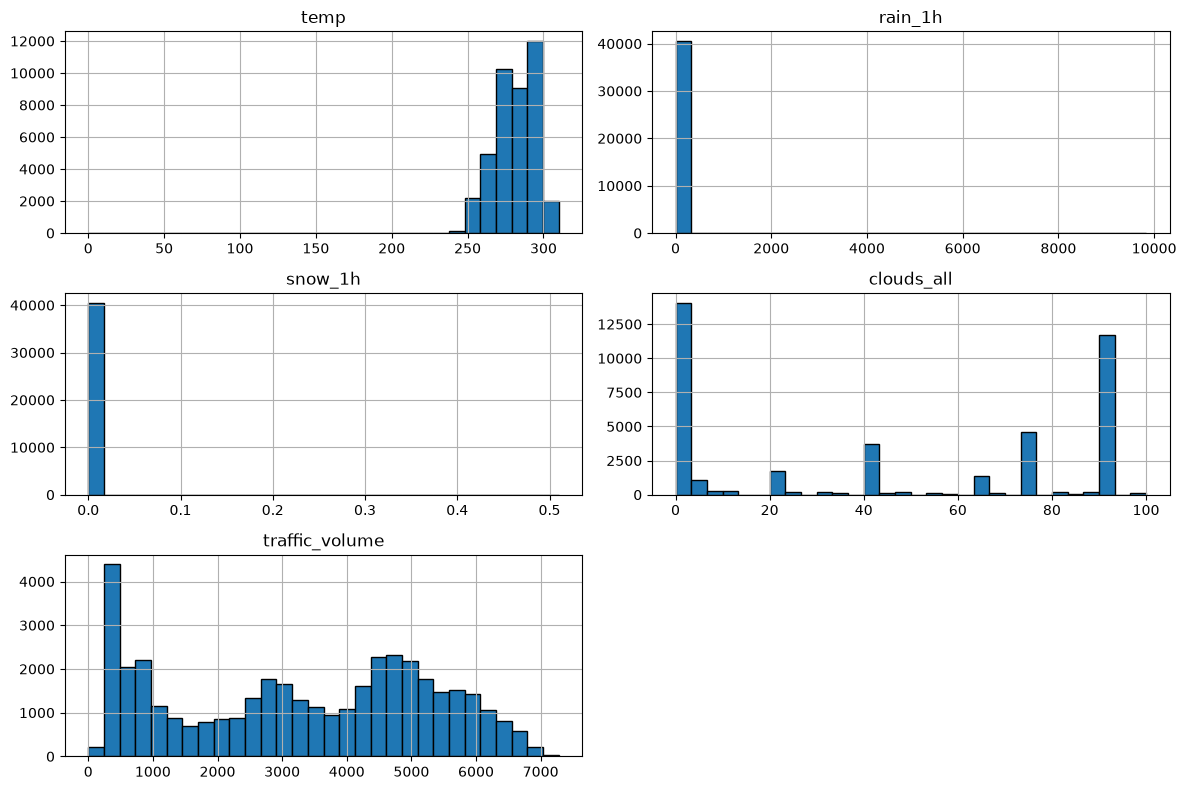

In [25]:
import matplotlib.pyplot as plt

numeric_columns = [
    "temp",
    "rain_1h",
    "snow_1h",
    "clouds_all",
    "traffic_volume"
]

df_clean[numeric_columns].hist(
    figsize=(12, 8),
    bins=30,
    edgecolor="black"
)

plt.tight_layout()
plt.show()

 the histograms show that the variables have different distribution patterns. Rainfall and snowfall contain many zero values, while traffic volume has substantial variation. These patterns will help guide our feature selection and forecasting preparation.

## Analytical Questions
### 1. How Does Traffic Volume Change Throughout the Day?

I will investigate how traffic volume varies by hour of the day. This will help me identify hours with higher or lower traffic and understand whether daily traffic patterns may be useful for forecasting.

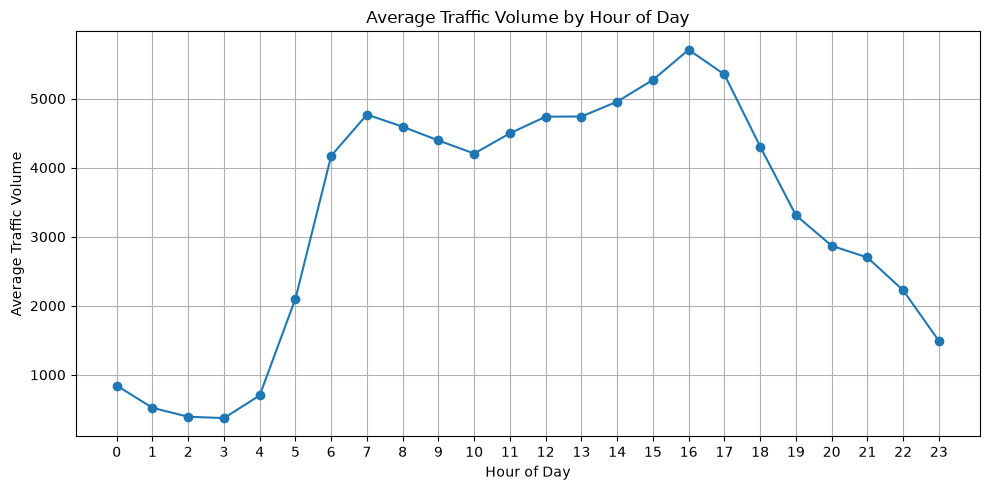

In [26]:
# Extract the hour from each timestamp
df_clean["hour"] = df_clean["date_time"].dt.hour

# Calculate average traffic volume for each hour
hourly_traffic = df_clean.groupby("hour")["traffic_volume"].mean()

# Visualize the hourly pattern
plt.figure(figsize=(10, 5))
plt.plot(hourly_traffic.index, hourly_traffic.values, marker="o")
plt.title("Average Traffic Volume by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Average Traffic Volume")
plt.xticks(range(24))
plt.grid(True)
plt.tight_layout()
plt.show()

The plot shows that traffic volume varies considerably throughout the day. Traffic is lowest during the early morning hours, especially around 2:00–3:00 AM. It begins increasing from around 4:00 AM and rises sharply between 5:00 AM and 7:00 AM.

Traffic remains relatively high during the daytime and reaches its highest average around 4:00 PM. After 5:00 PM, traffic decreases steadily into the night.

These patterns suggest that the hour of the day is an important feature for predicting traffic volume. I will therefore consider extracting the hour from the timestamp for forecasting.

### 2. Does traffic volume differ by day of the week?
I will compare average traffic volume across the days of the week to determine whether traffic patterns differ between weekdays and weekends. This may help identify useful calendar features for forecasting.

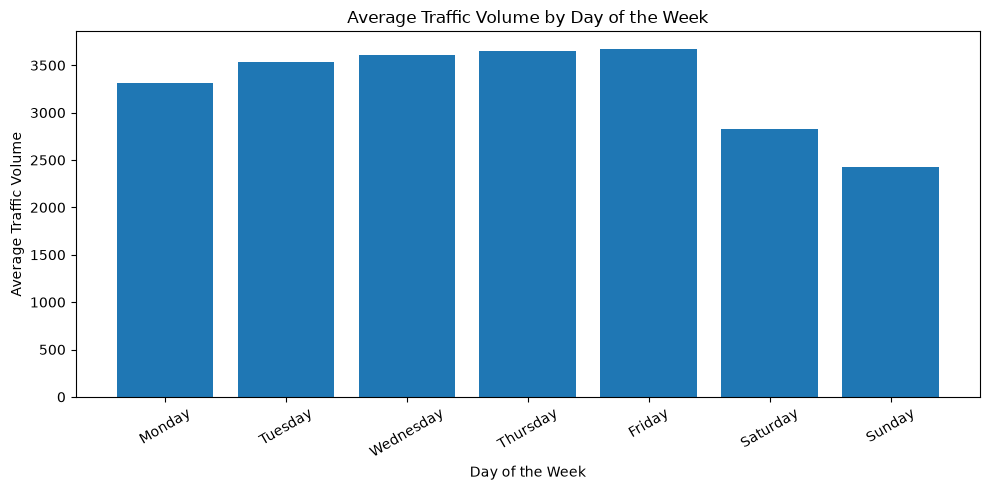

In [27]:
# Extract the day of the week
df_clean["day_of_week"] = df_clean["date_time"].dt.dayofweek

# Calculate average traffic volume by day
daily_traffic = df_clean.groupby("day_of_week")["traffic_volume"].mean()

# Display days in calendar order
day_names = ["Monday", "Tuesday", "Wednesday",
             "Thursday", "Friday", "Saturday", "Sunday"]

plt.figure(figsize=(10, 5))
plt.bar(day_names, daily_traffic.reindex(range(7)))
plt.title("Average Traffic Volume by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Traffic Volume")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

The plot shows differences in average traffic volume across the days of the week. Traffic is relatively high from Monday to Friday, with Friday having the highest average among the seven days.

Traffic volume decreases considerably on Saturday and reaches its lowest average on Sunday. This suggests that traffic patterns differ between weekdays and weekends.

The day of the week may therefore be a useful feature for forecasting traffic volume. I will consider creating a weekday or weekend feature during feature engineering.

### 3. Does Traffic Volume Show a Trend Over Time?

I will calculate and visualize the monthly average traffic volume to examine how traffic changes over the dataset's time range. This will help me identify possible long-term increases, decreases, or fluctuations. Months with no observations will remain missing rather than being filled with artificial values.

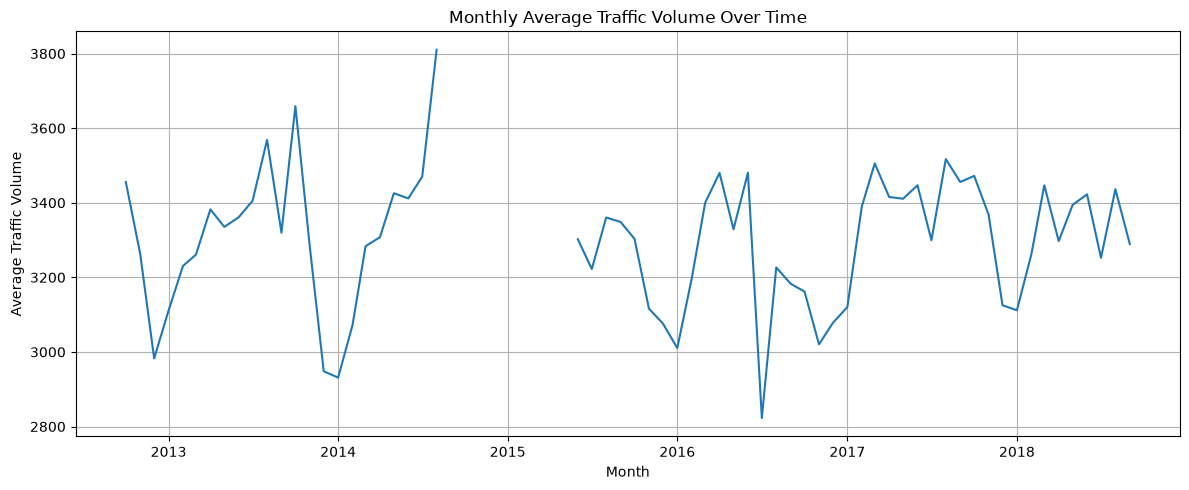

In [28]:
# Calculate monthly average traffic volume
monthly_traffic = (
    df_clean.set_index("date_time")["traffic_volume"]
    .resample("MS")
    .mean()
)

# Visualize the monthly trend
plt.figure(figsize=(12, 5))
plt.plot(monthly_traffic.index, monthly_traffic.values)
plt.title("Monthly Average Traffic Volume Over Time")
plt.xlabel("Month")
plt.ylabel("Average Traffic Volume")
plt.grid(True)
plt.tight_layout()
plt.show()

The monthly average traffic volume fluctuates throughout the dataset's time range. Some months show increases, while others show decreases. The plot does not reveal a consistent long-term upward or downward trend.

There are also gaps in the plotted timeline, reflecting periods with no recorded observations. Therefore, I cannot confidently interpret the changes as a continuous long-term trend.

The results suggest that traffic volume varies over time, but further forecasting analysis should account for the missing periods rather than treating the series as continuous.

### 4. Is Traffic Volume Related to the Previous Hour?

I will compare traffic volume with the traffic volume recorded one hour earlier. This lag analysis will help me determine whether recent traffic conditions are associated with the current traffic volume, which could be useful for forecasting.

Correlation with previous hour: 0.914


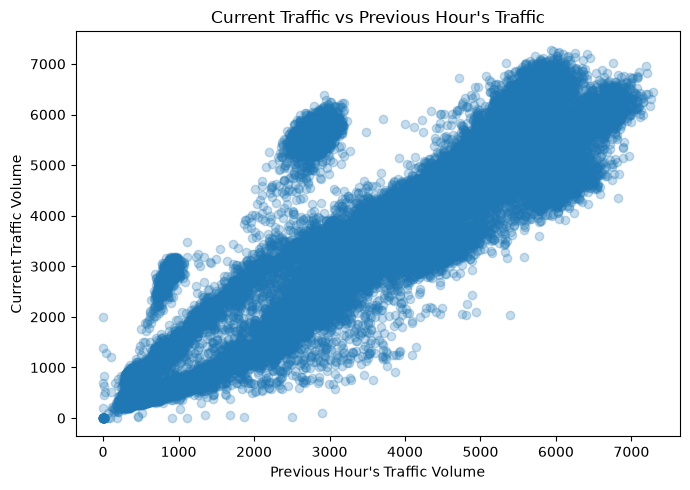

In [29]:
# Get the previous observation within each continuous hourly period
df_clean["traffic_lag_1"] = (
    df_clean.groupby("period_id")["traffic_volume"].shift(1)
)

lag_1_data = df_clean.dropna(subset=["traffic_lag_1"])

# Calculate correlation
lag_1_corr = lag_1_data["traffic_volume"].corr(
    lag_1_data["traffic_lag_1"]
)

print(f"Correlation with previous hour: {lag_1_corr:.3f}")

# Visualize the relationship
plt.figure(figsize=(7, 5))
plt.scatter(
    lag_1_data["traffic_lag_1"],
    lag_1_data["traffic_volume"],
    alpha=0.25
)
plt.title("Current Traffic vs Previous Hour's Traffic")
plt.xlabel("Previous Hour's Traffic Volume")
plt.ylabel("Current Traffic Volume")
plt.tight_layout()
plt.show()

The scatter plot shows a clear positive relationship between current traffic volume and traffic volume during the previous hour. As the previous hour's traffic volume increases, the current hour's traffic volume generally increases as well.

Although there is some variation, the overall pattern suggests that recent traffic conditions contain useful information about current traffic volume.

This indicates that a one-hour lag feature may be useful for forecasting. I will consider using previous traffic observations as input features in the forecasting model.

### 5. Are Daily Lag Effects and Weather Conditions Associated with Traffic Volume?

In this step, I will compare current traffic volume with traffic recorded 24 hours earlier to investigate whether traffic patterns repeat from one day to the next. I will also examine the relationships between traffic volume and the remaining weather variables: temperature, rainfall, snowfall, and cloud cover. Visualizations and correlation values will help me identify which variables may be useful for forecasting.

Correlation with traffic 24 hours earlier: 0.861


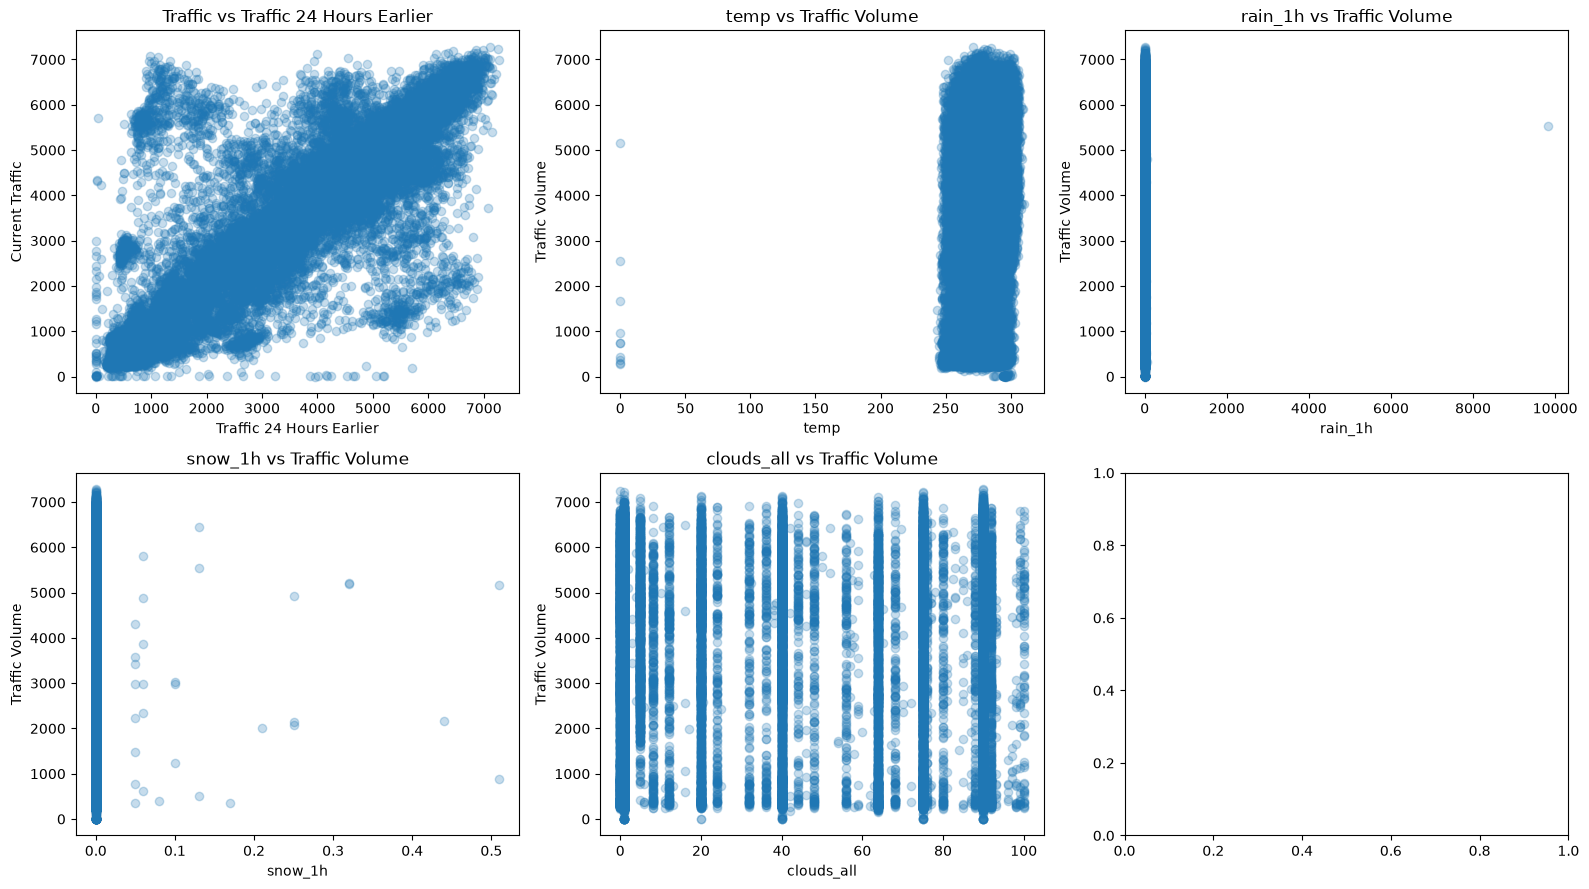


Weather correlations with traffic volume:
temp          0.137
clouds_all    0.078
rain_1h       0.005
snow_1h      -0.002
Name: traffic_volume, dtype: float64


In [30]:
# Compare traffic with traffic 24 hours earlier
df_clean["traffic_lag_24"] = (
    df_clean.groupby("period_id")["traffic_volume"].shift(24)
)

lag_24_data = df_clean.dropna(subset=["traffic_lag_24"])

lag_24_corr = lag_24_data["traffic_volume"].corr(
    lag_24_data["traffic_lag_24"]
)

print(f"Correlation with traffic 24 hours earlier: {lag_24_corr:.3f}")

# Plot the lag relationship and weather correlations
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

axes[0, 0].scatter(
    lag_24_data["traffic_lag_24"],
    lag_24_data["traffic_volume"],
    alpha=0.25
)
axes[0, 0].set_title("Traffic vs Traffic 24 Hours Earlier")
axes[0, 0].set_xlabel("Traffic 24 Hours Earlier")
axes[0, 0].set_ylabel("Current Traffic")

weather_columns = ["temp", "rain_1h", "snow_1h", "clouds_all"]

for ax, column in zip(axes.flatten()[1:], weather_columns):
    ax.scatter(df_clean[column], df_clean["traffic_volume"], alpha=0.25)
    ax.set_title(f"{column} vs Traffic Volume")
    ax.set_xlabel(column)
    ax.set_ylabel("Traffic Volume")

plt.tight_layout()
plt.show()

# Print correlations for the weather variables
print("\nWeather correlations with traffic volume:")
print(
    df_clean[weather_columns + ["traffic_volume"]]
    .corr()["traffic_volume"]
    .drop("traffic_volume")
    .sort_values(ascending=False)
    .round(3)
)

The plot comparing current traffic volume with traffic volume 24 hours earlier shows a positive relationship, although the observations are more widely scattered than in the previous-hour comparison. This suggests that traffic levels from the same hour on the previous day may provide useful forecasting information, but the relationship is not exact.

The weather scatter plots do not show clear strong relationships between traffic volume and temperature, rainfall, snowfall, or cloud cover. Rainfall and snowfall contain many values near zero, and the extreme rainfall value makes its relationship difficult to assess visually. Temperature also contains a suspicious zero value.

Based on these visual patterns, historical traffic volume appears more promising for forecasting than the weather variables alone. However, I will use the numerical correlation results and model experiments to assess their usefulness before making final feature-selection decisions.

### 6.How Do Moving Averages Reveal Traffic Patterns?

I will calculate a 3-hour, 6 hour, and a 24-hour moving average of traffic volume to examine short-term and daily traffic patterns. Moving averages smooth out some hourly fluctuations and help reveal broader changes in traffic volume. I will calculate them only within continuous hourly periods to avoid crossing gaps in the dataset.

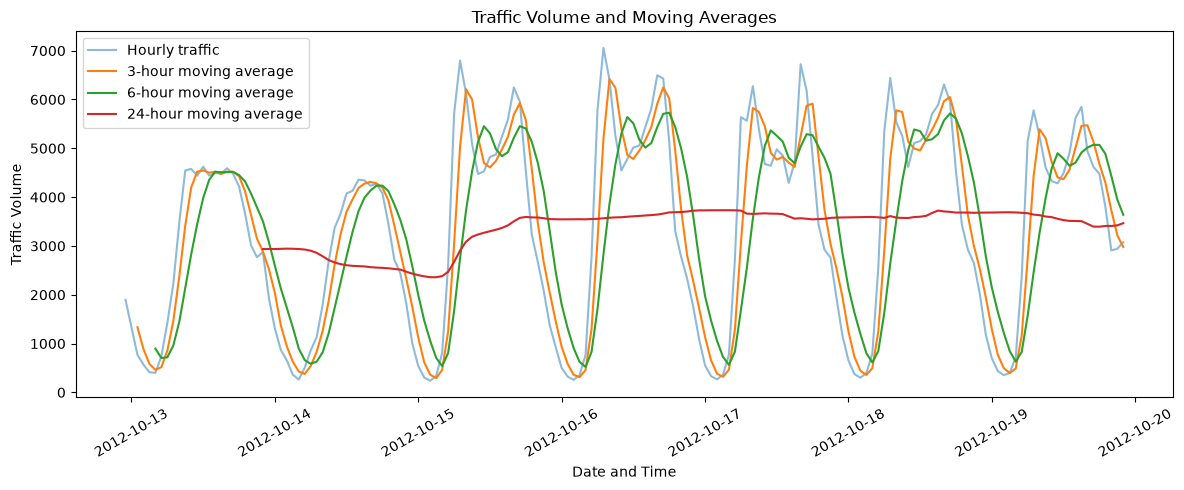

In [31]:
# Calculate moving averages within continuous periods
for window in [3, 6, 24]:
    df_clean[f"traffic_ma_{window}h"] = (
        df_clean.groupby("period_id")["traffic_volume"]
        .transform(lambda s: s.rolling(window=window, min_periods=window).mean())
    )

# Use the same continuous period for comparison
period = (
    df_clean.groupby("period_id").size()
    .loc[lambda s: s >= 168].index[0]
)

sample = df_clean[df_clean["period_id"] == period].head(168)

plt.figure(figsize=(12, 5))
plt.plot(sample["date_time"], sample["traffic_volume"],
         label="Hourly traffic", alpha=0.5)
plt.plot(sample["date_time"], sample["traffic_ma_3h"],
         label="3-hour moving average")
plt.plot(sample["date_time"], sample["traffic_ma_6h"],
         label="6-hour moving average")
plt.plot(sample["date_time"], sample["traffic_ma_24h"],
         label="24-hour moving average")

plt.title("Traffic Volume and Moving Averages")
plt.xlabel("Date and Time")
plt.ylabel("Traffic Volume")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

The plot also reveals a recurring pattern: traffic volume rises during busier hours and falls during quieter nighttime hours. The moving averages help reveal this pattern while reducing short-term fluctuations.

These results show that moving averages can help describe traffic patterns at different time scales. I will consider lagged traffic values and moving-average features when preparing the forecasting model, while ensuring that only past observations are used to predict future traffic.

### Selecting a Continuous Period for Forecasting

Before building a forecasting model, I need to select a continuous period with enough hourly observations. The dataset contains large gaps, so using the entire timeline as if every hour were observed could produce misleading lag features and moving averages. I will examine the longest continuous periods and select a suitable period for model development.

In [32]:
# Summarize the continuous periods
period_summary = (
    df_clean.groupby("period_id")
    .agg(
        start_time=("date_time", "min"),
        end_time=("date_time", "max"),
        observations=("traffic_volume", "count")
    )
    .reset_index()
)

period_summary["duration_days"] = (
    (period_summary["end_time"] - period_summary["start_time"])
    .dt.total_seconds() / 86400
)

# Show the 10 longest periods
period_summary.sort_values(
    "observations", ascending=False
).head(10)

,period_id,start_time,end_time,observations,duration_days
2564,2565,2017-04-13 10:00:00,2017-07-02 04:00:00,1915,79.750000
2586,2587,2018-06-02 03:00:00,2018-08-07 06:00:00,1588,66.125000
2555,2556,2016-12-18 19:00:00,2017-02-13 15:00:00,1365,56.833333
2514,2515,2016-07-13 18:00:00,2016-08-24 16:00:00,1007,41.916667
2570,2571,2017-09-28 00:00:00,2017-11-08 01:00:00,986,41.041667
2588,2589,2018-08-23 03:00:00,2018-09-30 23:00:00,933,38.833333
2578,2579,2018-01-31 03:00:00,2018-03-10 01:00:00,911,37.916667
778,779,2014-01-26 09:00:00,2014-03-04 14:00:00,894,37.208333
2584,2585,2018-03-29 03:00:00,2018-05-05 01:00:00,887,36.916667
2567,2568,2017-07-10 16:00:00,2017-08-16 03:00:00,876,36.458333


The period summary shows that the dataset contains several continuous periods of different lengths. The longest is period 2565, covering April 13, 2017, to July 2, 2017, with 1,915 observations over approximately 79.75 days.

I will use this period for the initial forecasting experiments because it provides the largest continuous segment in the dataset. Selecting a continuous period will help me create lagged features and moving averages without accidentally crossing large gaps in the timeline.

### Extracting the Selected Period

In this step, I will create a separate dataframe containing only period 2565 and verify its timestamps, number of observations, and hourly intervals before preparing the forecasting features.

In [33]:
# Select the longest continuous period
forecast_df = (
    df_clean[df_clean["period_id"] == 2565]
    .copy()
    .sort_values("date_time")
    .reset_index(drop=True)
)

# Verify the selected data
print("Number of observations:", len(forecast_df))
print("Start time:", forecast_df["date_time"].min())
print("End time:", forecast_df["date_time"].max())
print(
    "All intervals are one hour:",
    forecast_df["date_time"].diff().dropna().eq(
        pd.Timedelta(hours=1)
    ).all()
)

Number of observations: 1915
Start time: 2017-04-13 10:00:00
End time: 2017-07-02 04:00:00
All intervals are one hour: True


The output confirms that my selected forecasting dataset contains 1,915 observations, covering April 13, 2017, to July 2, 2017. All consecutive observations are exactly one hour apart.

This continuous period is suitable for preparing lagged features and moving averages without crossing missing time intervals. I will use this dataset to prepare the forecasting variables and compare forecasting models.

### Creating Time-Based and Lagged Features

In this step, I will extract the hour and day of the week from each timestamp and create traffic lag features for the previous hour and the same hour on the previous day. These features will allow the forecasting models to learn from daily traffic patterns and recent traffic conditions.

In [34]:
# Extract time-based features
forecast_df["hour"] = forecast_df["date_time"].dt.hour
forecast_df["day_of_week"] = forecast_df["date_time"].dt.dayofweek
forecast_df["is_weekend"] = (
    forecast_df["day_of_week"] >= 5
).astype(int)

# Create lag features
forecast_df["traffic_lag_1"] = forecast_df["traffic_volume"].shift(1)
forecast_df["traffic_lag_24"] = forecast_df["traffic_volume"].shift(24)

# Display a sample
forecast_df[
    [
        "date_time",
        "traffic_volume",
        "hour",
        "day_of_week",
        "is_weekend",
        "traffic_lag_1",
        "traffic_lag_24"
    ]
].head(27).tail(5)

,date_time,traffic_volume,hour,day_of_week,is_weekend,traffic_lag_1,traffic_lag_24
22,2017-04-14 08:00:00,5150,8,4,0,6026.0,NaN
23,2017-04-14 09:00:00,4809,9,4,0,5150.0,NaN
24,2017-04-14 10:00:00,4763,10,4,0,4809.0,4576.0
25,2017-04-14 11:00:00,5201,11,4,0,4763.0,5033.0
26,2017-04-14 12:00:00,5598,12,4,0,5201.0,5138.0


The first 23 observations have missing values for traffic_lag_24 because the dataset does not yet contain 24 earlier observations within the selected period. This is expected, not an error.

These features provide information about time and historical traffic that a forecasting model can use to predict future traffic volume.

### Creating Moving-Average Features

**What am I doing, and why?**

In this step, I will create two new features:

- `traffic_ma_3h`: the average traffic volume over the **previous 3 hours**.
- `traffic_ma_24h`: the average traffic volume over the **previous 24 hours**.

I am creating these features to help my model identify short-term traffic changes and daily traffic patterns.

One important forecasting rule I must follow is to use only traffic observations that are already available when making a prediction. Therefore, I will shift the traffic series by one hour before calculating the moving averages. This prevents the model from using the actual traffic volume of the hour it is trying to predict, avoiding data leakage.

In [35]:
# Calculate moving averages using past observations only
forecast_df["traffic_ma_3h"] = (
    forecast_df["traffic_volume"]
    .shift(1)
    .rolling(window=3)
    .mean()
)

forecast_df["traffic_ma_24h"] = (
    forecast_df["traffic_volume"]
    .shift(1)
    .rolling(window=24)
    .mean()
)

# Display the target and its forecasting features
forecast_df[
    [
        "date_time",
        "traffic_volume",
        "traffic_lag_1",
        "traffic_lag_24",
        "traffic_ma_3h",
        "traffic_ma_24h"
    ]
].iloc[20:28].round(2)

/tmp/ipykernel_348195/1739692026.py:26: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].iloc[20:28].round(2)


,date_time,traffic_volume,traffic_lag_1,traffic_lag_24,traffic_ma_3h,traffic_ma_24h
20,2017-04-14 06:00:00,5055,2425.0,NaN,1196.67,NaN
21,2017-04-14 07:00:00,6026,5055.0,NaN,2771.33,NaN
22,2017-04-14 08:00:00,5150,6026.0,NaN,4502.00,NaN
23,2017-04-14 09:00:00,4809,5150.0,NaN,5410.33,NaN
24,2017-04-14 10:00:00,4763,4809.0,4576.0,5328.33,3751.21
25,2017-04-14 11:00:00,5201,4763.0,5033.0,4907.33,3759.00
26,2017-04-14 12:00:00,5598,5201.0,5138.0,4924.33,3766.00
27,2017-04-14 13:00:00,5471,5598.0,5296.0,5187.33,3785.17


What I observe from the output
- traffic_ma_3h: The value for 2017-04-14 at 08:00 is 4502.00. This is the average traffic volume from the three previous hours: 05:00, 06:00, and 07:00.
- traffic_ma_24h: The first values are NaN because 24 previous hourly observations are not yet available. By 10:00 on April 14, the 24-hour moving average can be calculated.
- Lag features: traffic_lag_1 contains the previous hour's traffic, while traffic_lag_24 contains traffic from the same hour on the previous day.
- No data leakage: The moving averages use previous observations, not the actual traffic volume of the hour being predicted.

### Checking missing values in forecasting features
Before training a model, I will check how many missing values were created by the lag and moving-average features. The earliest rows are expected to have missing values because they do not have enough historical observations.

In [36]:
# Count missing values in each column
forecast_df[
    [
        "traffic_volume",
        "traffic_lag_1",
        "traffic_lag_24",
        "traffic_ma_3h",
        "traffic_ma_24h"
    ]
].isnull().sum()

traffic_volume     0
traffic_lag_1      1
traffic_lag_24    24
traffic_ma_3h      3
traffic_ma_24h    24
dtype: int64

These missing values are not evidence of a problem with the original dataset. They occur naturally when creating historical features.

### Removing rows with incomplete forecasting features
I will remove rows that do not have all the historical features needed by the model. Since these missing values occur at the beginning of the selected period, this should remove only a small number of observations.

In [37]:
# Keep only rows with complete forecasting features
features = [
    "traffic_lag_1",
    "traffic_lag_24",
    "traffic_ma_3h",
    "traffic_ma_24h"
]

forecast_model_df = forecast_df.dropna(subset=features).copy()

print("Rows before cleaning:", len(forecast_df))
print("Rows after cleaning:", len(forecast_model_df))
print("Missing values in required features:",
      forecast_model_df[features].isnull().sum().sum())

Rows before cleaning: 1915
Rows after cleaning: 1891
Missing values in required features: 0


In this step, I learned an important lesson: using dropna() without specifying columns can accidentally remove valid data because it checks every column, including columns that are not needed for the model.

### Splitting the data chronologically
Next, I will divide my dataset into training, validation, and testing sets. Since this is a time-series forecasting task, I must preserve the chronological order instead of randomly shuffling the data.

I will use:
- 70% for training: the model learns traffic patterns.
- 15% for validation: I compare model settings and tune hyperparameters.
- 15% for testing: I evaluate the final model on data it has not seen during training or tuning.

In [38]:
# Sort observations from oldest to newest
forecast_model_df = forecast_model_df.sort_values("date_time").reset_index(drop=True)

# Calculate split positions
n = len(forecast_model_df)
train_end = int(n * 0.70)
validation_end = int(n * 0.85)

# Split without shuffling
train_df = forecast_model_df.iloc[:train_end].copy()
validation_df = forecast_model_df.iloc[train_end:validation_end].copy()
test_df = forecast_model_df.iloc[validation_end:].copy()

# Display the size and date range of each set
for name, data in [
    ("Training", train_df),
    ("Validation", validation_df),
    ("Testing", test_df)
]:
    print(f"\n{name} rows: {len(data)}")
    print(f"Start: {data['date_time'].min()}")
    print(f"End:   {data['date_time'].max()}")



Training rows: 1323
Start: 2017-04-14 10:00:00
End:   2017-06-08 12:00:00

Validation rows: 284
Start: 2017-06-08 13:00:00
End:   2017-06-20 08:00:00

Testing rows: 284
Start: 2017-06-20 09:00:00
End:   2017-07-02 04:00:00


In [39]:
# Check the dataset prepared for modeling
print("Dataset shape:", forecast_model_df.shape)
print("column:", forecast_model_df.columns)
print("Number of continuous periods:", forecast_model_df["period_id"].nunique())

Dataset shape: (1891, 18)
column: Index(['date_time', 'holiday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all',
       'weather_main', 'weather_description', 'traffic_volume', 'period_id',
       'hour', 'day_of_week', 'traffic_lag_1', 'traffic_lag_24',
       'traffic_ma_3h', 'traffic_ma_6h', 'traffic_ma_24h', 'is_weekend'],
      dtype='str')
Number of continuous periods: 1


In [40]:
# Remove the holiday column because it contains mostly missing values
forecast_model_df = forecast_model_df.drop(columns=["holiday"], errors="ignore")

# Verify the updated dataset
print("Dataset shape:", forecast_model_df.shape)
print("Holiday column present:", "holiday" in forecast_model_df.columns)
print("Missing values:", forecast_model_df.isnull().sum().sum())

Dataset shape: (1891, 17)
Holiday column present: False
Missing values: 0


### Final Forecasting Dataset Preparation and Chronological Split Decisions

In this steps, I prepared the final dataset for model training. I selected continuous period `2565`, which contained 1,915 hourly observations, to ensure that my lagged features and moving averages would not cross missing-time gaps.

After creating the historical features, I removed the initial 24 rows that lacked sufficient past observations. This left me with 1,891 observations and 16 columns. I also removed the `holiday` column because it contained too many missing values to be used reliably.

I then divided the data chronologically into three sets:

- **Training:** 1,323 observations (70%)
- **Validation:** 284 observations (15%)
- **Testing:** 284 observations (15%)

I preserved the time order to simulate predicting future traffic from past observations. I will use the training set to fit the models, the validation set to compare experiments and tune hyperparameters, and the test set only for final evaluation.

Although the dataset is now complete and suitable for our planned experiments, it represents approximately 80 days of traffic observations. Therefore, the model's performance may not generalize to every season or unusual traffic condition, but for its feture better performance I decided that I could retrain it on other periods to avoid inventing missing 308 days to achieve continueous period.

## 3. Model Training and Hyperparameter Tuning

In this section, I will train and evaluate machine learning models to predict traffic volume. I will begin with a simple baseline model and compare its performance with a Random Forest Regressor.

I will use the training set to fit the models and the validation set to compare experiments and tune hyperparameters. I will preserve the chronological order of the data and use the test set only for the final evaluation.

I will record the results of each experiment in a comparison table using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE). These metrics will help me determine which model makes more accurate predictions. Lower MAE and RMSE values indicate better predictive performance.

In [41]:
print("Training columns:")
print(train_df.columns.tolist())

print("\nValidation columns:")
print(validation_df.columns.tolist())

print("\nTesting columns:")
print(test_df.columns.tolist())

Training columns:
['date_time', 'holiday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main', 'weather_description', 'traffic_volume', 'period_id', 'hour', 'day_of_week', 'traffic_lag_1', 'traffic_lag_24', 'traffic_ma_3h', 'traffic_ma_6h', 'traffic_ma_24h', 'is_weekend']

Validation columns:
['date_time', 'holiday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main', 'weather_description', 'traffic_volume', 'period_id', 'hour', 'day_of_week', 'traffic_lag_1', 'traffic_lag_24', 'traffic_ma_3h', 'traffic_ma_6h', 'traffic_ma_24h', 'is_weekend']

Testing columns:
['date_time', 'holiday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main', 'weather_description', 'traffic_volume', 'period_id', 'hour', 'day_of_week', 'traffic_lag_1', 'traffic_lag_24', 'traffic_ma_3h', 'traffic_ma_6h', 'traffic_ma_24h', 'is_weekend']


In [42]:
for df in [train_df, validation_df, test_df]:
    df.drop(columns=["holiday"], errors="ignore", inplace=True)

print("Holiday in training:", "holiday" in train_df.columns)
print("Holiday in validation:", "holiday" in validation_df.columns)
print("Holiday in testing:", "holiday" in test_df.columns)

Holiday in training: False
Holiday in validation: False
Holiday in testing: False


### Experiment 1: Baseline Model. 
This model predicts the next hour's traffic volume using the previous hour's traffic volume. It provides a simple benchmark for evaluating the machine learning models.

In [43]:
# Actual traffic volumes
y_val = validation_df["traffic_volume"]

# Predict using the previous hour's traffic volume
baseline_predictions = validation_df["traffic_lag_1"]

baseline_mae = mean_absolute_error(y_val, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_val, baseline_predictions))

print("Baseline Validation MAE:", round(baseline_mae, 2))
print("Baseline Validation RMSE:", round(baseline_rmse, 2))

Baseline Validation MAE: 558.58
Baseline Validation RMSE: 794.13


### Experiment 2: Initial Random Forest Regressor. 
This model uses historical traffic patterns, time-based features, and weather information from previous hours to predict traffic volume.

In [44]:
features_a = [
    "temp",
    "rain_1h",
    "snow_1h",
    "clouds_all",
    "hour",
    "day_of_week",
    "is_weekend",
    "traffic_lag_1",
    "traffic_lag_24",
    "traffic_ma_3h",
    "traffic_ma_24h"
]

X_train_a = train_df[features_a]
y_train = train_df["traffic_volume"]

X_val_a = validation_df[features_a]
y_val = validation_df["traffic_volume"]

rf_initial = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

rf_initial.fit(X_train_a, y_train)

initial_predictions = rf_initial.predict(X_val_a)

initial_mae = mean_absolute_error(y_val, initial_predictions)
initial_rmse = np.sqrt(mean_squared_error(y_val, initial_predictions))

print("Initial Random Forest Validation MAE:", round(initial_mae, 2))
print("Initial Random Forest Validation RMSE:", round(initial_rmse, 2))

Initial Random Forest Validation MAE: 190.0
Initial Random Forest Validation RMSE: 287.16


### Experiment 3: Weather-Informed Random Forest Regressor. 
This model uses historical traffic patterns, time-based features, and weather information recorded for the hour being predicted. This experiment helps us investigate whether additional weather information improves prediction performance. Because the dataset contains observed weather rather than weather forecasts, this experiment is a comparison rather than a true real-time forecasting setup.

In [45]:
features = [
    "temp", "rain_1h", "snow_1h", "clouds_all",
    "hour", "day_of_week", "is_weekend",
    "traffic_lag_1", "traffic_lag_24",
    "traffic_ma_3h", "traffic_ma_24h"
]

X_train = train_df[features]
y_train = train_df["traffic_volume"]

X_val = validation_df[features]
y_val = validation_df["traffic_volume"]

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20, None],
    "min_samples_leaf": [1, 2, 4]
}

time_split = TimeSeriesSplit(n_splits=3)

grid_search = GridSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),
    param_grid=param_grid,
    cv=time_split,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

tuned_model = grid_search.best_estimator_
tuned_predictions = tuned_model.predict(X_val)

tuned_mae = mean_absolute_error(y_val, tuned_predictions)
tuned_rmse = np.sqrt(mean_squared_error(y_val, tuned_predictions))

print("Best hyperparameters:", grid_search.best_params_)
print("Best training cross-validation MAE:", round(-grid_search.best_score_, 2))
print("Tuned model validation MAE:", round(tuned_mae, 2))
print("Tuned model validation RMSE:", round(tuned_rmse, 2))

Best hyperparameters: {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 200}
Best training cross-validation MAE: 213.21
Tuned model validation MAE: 187.25
Tuned model validation RMSE: 287.5


In [46]:
results = pd.DataFrame([
    {
        "Experiment": "Previous-hour baseline",
        "Validation MAE": baseline_mae,
        "Validation RMSE": baseline_rmse
    },
    {
        "Experiment": "Initial Random Forest",
        "Validation MAE": initial_mae,
        "Validation RMSE": initial_rmse
    },
    {
        "Experiment": "Tuned Random Forest",
        "Validation MAE": tuned_mae,
        "Validation RMSE": tuned_rmse
    }
])

results["MAE reduction vs baseline (%)"] = (
    (baseline_mae - results["Validation MAE"]) / baseline_mae * 100
)

results["RMSE reduction vs baseline (%)"] = (
    (baseline_rmse - results["Validation RMSE"]) / baseline_rmse * 100
)

# Create the experiments folder
experiments_dir = Path("experiments")
experiments_dir.mkdir(parents=True, exist_ok=True)

# Save the comparison table
results_path = experiments_dir / "model_comparison.csv"
results.round(2).to_csv(results_path, index=False)

print(f"Experiment table saved to: {results_path}")

display(results.round(2))

Experiment table saved to: experiments/model_comparison.csv


,Experiment,Validation MAE,Validation RMSE,MAE reduction vs baseline (%),RMSE reduction vs baseline (%)
0,Previous-hour baseline,558.58,794.13,0.00,0.00
1,Initial Random Forest,190.00,287.16,65.99,63.84
2,Tuned Random Forest,187.25,287.50,66.48,63.80


The previous-hour baseline achieved a validation MAE of 558.58 and RMSE of 794.13. The initial Random Forest substantially improved performance, reducing MAE by approximately 66.48% and RMSE by 63.80% compared with the baseline.

After hyperparameter tuning, the Random Forest achieved a validation MAE of 187.25 and RMSE of 287.50. Compared with the initial Random Forest, tuning reduced MAE by approximately 1.45%, while RMSE increased slightly by approximately 0.12%.

These results show that Random Forest models predict traffic volume considerably better than the previous-hour baseline on this validation set. However, hyperparameter tuning produced only a small improvement, and the tuned model did not achieve the lowest RMSE. I will use the test set to evaluate the selected model's performance on unseen data before saving it.

### Evaluate the selected model on unseen data
Since the tuned Random Forest achieved the lower validation MAE, I'll select it using our validation results and evaluate it on the test set. This avoids choosing a model based on its test performance.

In [48]:
# Use the selected tuned model
best_model = tuned_model

# Prepare unseen test data
X_test = test_df[features]
y_test = test_df["traffic_volume"]

# Generate predictions
test_predictions = best_model.predict(X_test)

# Evaluate performance
test_mae = mean_absolute_error(y_test, test_predictions)
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))

print("Selected model: Tuned Random Forest")
print("Test rows:", len(test_df))
print("Test MAE:", round(test_mae, 2))
print("Test RMSE:", round(test_rmse, 2))

Selected model: Tuned Random Forest
Test rows: 284
Test MAE: 173.08
Test RMSE: 249.35


## Conclusion and Future Improvements

In this notebook, I cleaned and explored the Metro Interstate Traffic Volume dataset, investigated traffic patterns, and prepared the data for time-series forecasting. I engineered features such as hour, day of the week, previous-hour traffic, previous-day traffic, and moving averages to help the models learn from historical traffic patterns.

I evaluated three approaches: a previous-hour baseline, an initial Random Forest Regressor, and a tuned Random Forest Regressor. The tuned Random Forest was selected for the final evaluation.

### Final Test Results

The selected model was evaluated on 284 unseen observations and achieved the following results:

- **Test MAE:** 173.08
- **Test RMSE:** 249.35

These results indicate that the model's predictions differed from the actual traffic volumes by an average absolute error of approximately 173 vehicles per hour. The RMSE of 249.35 indicates that larger prediction errors have a greater effect on the overall error measure.

The results provide an encouraging starting point for traffic volume forecasting. However, the model was evaluated on one continuous period of approximately 80 days, so its performance may differ across other periods and traffic conditions.

### Future Improvements

In the next stage of the project, I plan to:

1. **Train and evaluate on additional periods:** Use other continuous periods from the dataset to determine whether the model performs consistently across different traffic conditions and seasons.
2. **Improve feature engineering:** Explore additional time-based features, alternative lag values, and moving-average windows to improve predictions while preventing data leakage.
3. **Compare more machine learning models:** Evaluate alternatives such as Linear Regression, Gradient Boosting, and other suitable forecasting models.
4. **Explore deep learning:** Test models such as LSTM or other time-series neural networks to determine whether they can capture more complex traffic patterns.
5. **Improve forecasting realism:** Use weather forecasts or only information available at prediction time when predicting future traffic volumes.
6. **Evaluate generalization:** Compare model performance across multiple chronological test periods to understand how reliably it predicts unseen traffic.

Overall, this notebook establishes a baseline forecasting pipeline and a tuned Random Forest model that can be improved in future experiments. By testing additional periods, engineering better features, and comparing more machine learning and deep learning approaches, I aim to identify a model that produces reliable traffic volume predictions under different conditions.